# Proyecto **Centinela** — Fase 2 (Sistema multimodal especializado)
### Redes Neuronales — Deep Learning · Maestría en Ciencia de Datos · Universidad Santo Tomás

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JuSeUlloa/Hurto-Personas-Centinela/blob/main/proyecto_centinela/02_scaffold_centinela_fase2.ipynb)

Andamiaje guía para la **Fase 2**: transformar la línea base de la Fase 1 (MLP tabular) en un **sistema multimodal especializado** — **rama A** (CNN sobre imágenes de luz nocturna VIIRS), **rama B** (LSTM/GRU sobre la serie municipal de tasa) y **rama C** (fusión por concatenación con estudio de ablación), sobre el **mismo problema y el mismo cliente** de la Fase 1.

> **Datos reales del proyecto** (propuesta v2, aprobada): **API del panel** — `bronze` (huella `e46ba559…`) y `gold` (`912b0add…`). Ventana publicada: **2021 + ene–feb 2022**. Las celdas de soporte de este andamiaje usan **datos sintéticos de demostración** hasta conectar la carga real (como en la Fase 1: primero la mecánica, después el dato).

> ⚠️ **Estado de la rama A:** las imágenes VNP46A3 requieren **cuenta NASA Earthdata** .

**Contenido**
0. Preparación del entorno
1. Rama A — CNN (imágenes de luz nocturna por municipio-mes)
2. Rama B — RNN/LSTM/GRU (serie municipal de tasa)
3. Rama C — Fusión multimodal + ablación
4. Lista de verificación de entrega + rúbrica

**Referencias del proyecto:** [`propuesta-de-datos-fase1.md`](./propuesta-de-datos-fase1.md) (v2) · [`informe-tecnico-etico-fase1.md`](./informe-tecnico-etico-fase1.md) · [`bitacora-ia.md`](./bitacora-ia.md) (continúa desde E-8) · cuaderno de la Fase 1 `02_scaffold_centinela_fase1.ipynb`.

## Preparación del entorno

Se importan las librerías de soporte y se fija la **semilla** (42, la misma de la **Fase 1.***). Para la Fase 2 se añaden `torch` y `torchvision`; el andamiaje de soporte solo requiere `numpy`/`sklearn`/`matplotlib`.


In [1]:
# En Colab estas librerías ya vienen instaladas. Si faltara alguna, descomentar:
# !pip -q install scikit-learn matplotlib torch torchvision

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset, DataLoader
import torchvision  

SEMILLA = 42
np.random.seed(SEMILLA)

try:
    torch.manual_seed(SEMILLA)
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    TORCH_OK = True
except Exception as e:  
    torch = None
    TensorDataset = DataLoader = None
    DEVICE = "cpu"
    TORCH_OK = False
    print("Aviso: PyTorch no está disponible en este entorno ->", e)
    print("Las celdas de soporte que no usan torch seguirán funcionando.")

try:
    TORCHVISION_OK = True
except Exception:
    torchvision = None
    TORCHVISION_OK = False

USTA_MORADO, USTA_ROSA, USTA_NAVY = "#3D008D", "#ED1E79", "#001A4D"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True, "grid.alpha": 0.3})


def miles(n):
    return f"{int(n):,}".replace(",", ".")

print("Entorno de soporte listo · numpy", np.__version__)
print(f"PyTorch disponible: {TORCH_OK}   ·   torchvision disponible: {TORCHVISION_OK}   ·   device: {DEVICE}")


Entorno de soporte listo · numpy 2.5.4
PyTorch disponible: True   ·   torchvision disponible: True   ·   device: cpu


> Política de datos del Proyecto Centinela, Las celdas de soporte de este andamiaje emplean datos sintéticos de demostración para validar la mecánica del flujo. La configuración real del proyecto es la siguiente:
> - **Serie (Rama B)**: eventos de hurto a personas agregados por `(departamento, municipio, año-mes)` obtenido de la API `bronze`; tasa por 100.000 hab. con población DANE del obtenida de `gold` con **8.042 observaciones** 
> - **Imágenes (rama A)**: recortes **VNP46A3** por municipio-mes (DOI 10.5067/VIIRS/VNP46A3.002)
> - **Poligonos por municipio**: API `municipios` (polígonos del municipio para recorte de imágenes)
> - **Etiquetas**: la alerta binaria del proyecto (tasa del mes > P75 del propio municipio, sin fuga — misma etiqueta usada en la Fase 1) y, para el requisito de ≥3 categorías de la rama A, se aplica el tercil de población del municipio (cortes ≈10.464 / ≈25.186 hab → 343/343/341)

## 1. Rama A — CNN (imágenes de luz nocturna VIIRS por municipio-mes)

**El concepto de "imagen" para la Fase 2 de Centinela :** no son fotografías, son recortes del mapa de luz nocturna (VNP46A3) por el polígono de cada municipio obtenido de la API `municipios` en cada mes: una matriz donde cada píxel es la radiancia de luz artificial. La CNN aprende a leer la **huella urbana** (mancha brillante = cabecera urbana; negro = rural).

**requisitos de la actividad:**
- **Más de 500 imágenes**: la ventana produce **8.042 pares** (municipio, mes) — cada uno un recorte (16× el mínimo)
- **3 o más categorías**: el **tercil de población** del municipio (pequeño / medio / grande — cortes ≈10.464 y ≈25.186 hab; 343/343/341). La decisión se declara en el cuaderno y se ratifica con el docente (la actividad lo admite explícitamente)
- **Partición 70/15/15**: por **MUNICIPIO**: evita que recortes del mismo territorio-mes estén en train y test (las luces de un municipio casi no cambian en 30 días → fuga espaciotemporal). El modelo fusionado se evalúa luego en la partición temporal de la Fase 1
- **Transfer Learning con dominio distinto**: los recortes son **monocanal** (radiancia) — se apilan 3 capas del producto (radiancia + variabilidad + nubes) como pseudo-RGB, y el dominio tan distinto de ImageNet justifica **Feature Extraction congelado** frente a Fine-Tuning (decisión que exige la rúbrica)
- **Recortes Por municipio**:la descarga VNP46A3 requiere cuenta NASA Earthdata con 14 compuestos mensuales, uno por mes de la ventana, se descargaron 126 archivos.h5 que actúa como un contenedor multidimensional que almacena múltiples capas científicas. 

> 📝 **Requerimientos para Rama A**
> 1. Importar `torch`/`torchvision` y fijar `torch.manual_seed(SEMILLA)`.
> 2. Comparar **al menos dos arquitecturas preentrenadas** (ResNet50 y EfficientNet-B0 recomendadas) por parámetros, profundidad e inferencia, y **justificar Feature Extraction vs Fine-Tuning** — en nuestro dominio (monocanal nocturno ≠ ImageNet), el congelado es la justificación a escribir.
> 3. Adaptar la cabeza de clasificación a 3 clases (tercil de población), con **data augmentation pertinente** al dominio
> 4. Entrenar con **early stopping + checkpoints** en Drive 
> 5. **Grad-CAM** para verificar que la red mira la mancha urbana (eleva a Estratégico).

In [2]:
import os, re, json, datetime, urllib.request, urllib.error, hashlib, collections
import geopandas as gpd
import numpy as np
import urllib.request, urllib.error
import rioxarray 

def leer_env(ruta=".env"):
    if os.path.exists(ruta):
        for linea in open(ruta, encoding="utf-8"):
            linea = linea.strip()
            if linea and not linea.startswith("#") and "=" in linea:
                k, _, v = linea.partition("=")
                os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))
    return os.environ

leer_env(".env")
USUARIO = os.environ.get("EARTHDATA_USERNAME")
CLAVE   = os.environ.get("EARTHDATA_PASSWORD")
TOKEN   = os.environ.get("EARTHDATA_TOKEN")

if not (USUARIO and CLAVE):
    raise RuntimeError(
        "Crea un archivo .env en la raíz del proyecto (se ignora en git) con:\n"
        "  EARTHDATA_USERNAME=tu_usuario\n"
        "  EARTHDATA_PASSWORD=tu_contraseña\n"
        "y recuerda aprobar la aplicación «NASA LAADS DAAC» en tu perfil URS.")


req = urllib.request.Request(
    "https://ladsweb.modaps.eosdis.nasa.gov/archive/README",
    headers={"Authorization": f"Bearer {TOKEN}"})
try:
    r = urllib.request.urlopen(req, timeout=60)
    print("HTTP", r.status, "· acceso a LAADS confirmado ✓")
    print(r.read().decode()[:120])
except urllib.error.HTTPError as e:
    print(f"HTTP {e.code} · acceso denegado ✗")
    print("→ verifica: (1) token vigente (regenerar en URS profile), "
          "(2) la aplicación aprobada, (3) que copiaste el token completo")

LAADS = "https://ladsweb.modaps.eosdis.nasa.gov"
CLASES = ["pequeno", "medio", "grande"]        


import http.cookiejar

frasco = http.cookiejar.CookieJar()
opener = urllib.request.build_opener(urllib.request.HTTPCookieProcessor(frasco))

def get(url):
    req = urllib.request.Request(url, headers={"Authorization": f"Bearer {TOKEN}"})
    try:
        return opener.open(req, timeout=300)
    except urllib.error.HTTPError as e:
        if e.code == 401:
            raise RuntimeError(
                "LAADS devolvió 401 en la descarga. Prueba en orden: "
                "(1) verifica que el token sea vigente (regenerar en urs.earthdata.nasa.gov/profile → "
                "Generate Token — expiran a los 60 días); "
                "(2) genera también el «LAADS DAAC token» en la propia página de LAADS "
                "(botón 'Generate LAADS DAAC token') y ponlo en el .env como EARTHDATA_TOKEN; "
                "(3) confirma que la aplicación «NASA LAADS DAAC» o «LAADS DAAC Cumulus (PROD)» "
                "esté aprobada en tu perfil.") from e
        raise



HTTP 200 · acceso a LAADS confirmado ✓
***************************************
* LAADS and DATAPOOL DATA ReadMe File *
***************************************



In [3]:
gold   = json.loads(get("https://intelligence-territorial-panel.vercel.app/api/dbx/gold").read())["response"]
bronce = json.loads(get("https://intelligence-territorial-panel.vercel.app/api/dbx/bronze").read())["response"]
POB = {r["codigo_dane"]: int(r["pob_dane_2025"]) for r in gold}
cods = sorted(POB.values())
C1, C2 = cods[len(cods)//3], cods[2*len(cods)//3]

clave = lambda r: (r["departamento"], r["municipio"])
pref5 = lambda codigo: codigo.zfill(8)[:5]
pref_cant = collections.defaultdict(collections.Counter)
for r in bronce:
    pref_cant[clave(r)][pref5(r["codigo_dane"])] += 1
COD5  = {kk: max(pref, key=pref.get) for kk, pref in pref_cant.items()}
CLASE = {kk: ("pequeno" if POB[COD5[kk]] <= C1 else
              ("medio" if POB[COD5[kk]] <= C2 else "grande")) for kk in pref_cant}
print(f"terciles de población: cortes {C1:,} / {C2:,} hab. · municipios con código: {len(COD5)}")

terciles de población: cortes 9,402 / 23,540 hab. · municipios con código: 1026


### Para la rama A, se recomienda usar **Feature Extraction congelado** (Fine-Tuning parcial opcional a comparar) y **Grad-CAM** para verificar que la red mira la mancha urbana. La celda siguiente está intencionalmente incompleta (sintética de demostración). El bloqueo real es la descarga VNP46A3 (cuenta Earthdata) — el código de descarga y se ejecuta al quedar disponible la cuenta.

si no tienes cuenta Earthdata, puedes usar los archivos h5 que el script descarga producto VNP46A3 almacenadas en capeta oneDrive https://usantotomaseduco-my.sharepoint.com/:u:/r/personal/juan_ulloa_usantotomas_edu_co/Documents/VIIRS/imagenes_municipios_mes_viirs.zip?d=wc96e815ba89c4c2293cc9bffc994c3c9&csf=1&web=1&e=WvzNc0 se debe almacerar en la carpeta de trabajo /data/vnp46a3 que fueron generadas con el script de procesamiento.

In [4]:
import h5py
import rasterio
from rasterio.transform import from_bounds
from blackmarble.download import TILES
import geopandas as gpd

## Descarga de compuestos mensuales VNP46A3 (radiancia nocturna) por (mes, tile) → data/vnp46a3/
def descargar(url, destino, intentos=4):
    import time
    for intento in range(1, intentos + 1):
        try:
            req = urllib.request.Request(url, headers={"Authorization": f"Bearer {TOKEN}"})
            with opener.open(req, timeout=600) as r, open(destino + ".part", "wb") as f:
                while True:
                    bloque = r.read(1 << 20)             
                    if not bloque:
                        break
                    f.write(bloque)
            try:
                with h5py.File(destino + ".part", "r") as _f:
                    _ = _f["HDFEOS/GRIDS/VIIRS_Grid_DNB_2d/Data Fields/NearNadir_Composite_Snow_Free"].shape
            except Exception:
                os.remove(destino + ".part")
                raise IOError(f"archivo truncado: {destino}.part → reintentando")
            os.replace(destino + ".part", destino)  
            return os.path.getsize(destino)
        except (TimeoutError, urllib.error.URLError, ConnectionError, OSError) as e:
            if os.path.exists(destino + ".part"):
                os.remove(destino + ".part")        
            print(f"  ⚠ intento {intento}/{intentos} falló ({type(e).__name__}: {e}) → reintentando…")
            time.sleep(10 * intento)
    raise RuntimeError(f"No se pudo descargar {url} tras {intentos} intentos.")



tiles_col = sorted(TILES.cx[-80:-66, -4:13]["TileID"])
MESES = [(2021, m) for m in range(1, 13)] + [(2022, m) for m in (1, 2)]
print(f"tiles de Colombia: {tiles_col} · meses: {len(MESES)}")

os.makedirs("data/vnp46a3", exist_ok=True)
ESCALA = 100.0    
descargados, omitidos = [], []
for (anio, mes) in MESES:
    doy = datetime.datetime(anio, mes, 1).timetuple().tm_yday
    listado = f"{LAADS}/archive/allData/5200/VNP46A3/{anio}/{doy:03d}/"
    for tile in tiles_col:
        try:
            html = opener.open(urllib.request.Request(listado, headers={'Authorization': f'Bearer {TOKEN}'}), timeout=600).read().decode("utf-8", errors="replace")
            patron = rf"VNP46A3\.A{anio}{doy:03d}\.{re.escape(tile)}\.002\.\d+\.h5"
            nombres = re.findall(patron, html)
        except urllib.error.HTTPError as e:
            nombres = []
            print(f"  {anio}-{mes:02d} {tile}: HTTP {e.code} → se omite")
        if not nombres:
            omitidos.append((anio, mes, tile)); continue
        nombre = nombres[0]
        destino = os.path.join("data/vnp46a3", nombre)
        if os.path.exists(destino) and os.path.getsize(destino) > 0:
            descargados.append(destino); continue
        n_bytes = descargar(f"{listado}{nombre}", destino)
        descargados.append(destino)
        print(f"  ✔ {nombre} · {n_bytes/1e6:.1f} MB · sha256[:16] {hashlib.sha256(open(destino, 'rb').read()).hexdigest()[:16]}")
print(f"compuestos: {len(descargados)} descargados · {len(omitidos)} omitidos")

# ── 5) recortes por municipio → data/imagenes/{tercil}/ ──
# cada municipio se asigna a SU tile (por centroide) una sola vez

# mapa código DANE (5 dígitos, formato del gpkg) → clase de tercil:
# COD5 ya resuelve el código dominante de cada (departamento, municipio) — celda 7.
CLASE_COD = {COD5[kk]: cls for kk, cls in CLASE.items()}
print(f"clases por código DANE: {len(CLASE_COD)} municipios con tercil asignado")

mgn_local = gpd.read_file("data/MGN/municipios_api.gpkg")
mgn_local["centro"] = mgn_local.geometry.representative_point()
unido = gpd.sjoin(mgn_local.set_geometry("centro"), TILES[["TileID", "geometry"]],
                  how="left", predicate="within")
MUNI_TILE = dict(zip(unido["codigo_dane"], unido["TileID"]))
MUNI_GEOM = dict(zip(mgn_local["codigo_dane"], mgn_local.geometry))

os.makedirs("data/imagenes", exist_ok=True)
hechos = collections.Counter()
for ruta_h5 in descargados:
    nombre = os.path.basename(ruta_h5)
    anio = int(nombre.split(".")[1][1:5])
    doy  = int(nombre.split(".")[1][5:8])
    fecha = datetime.datetime(anio, 1, 1) + datetime.timedelta(days=doy - 1)
    y, m = fecha.year, fecha.month
    tile = nombre.split(".")[2]
    with h5py.File(ruta_h5, "r", swmr=True) as h5:
        attrs = h5.attrs
        campo = h5["HDFEOS/GRIDS/VIIRS_Grid_DNB_2d/Data Fields/NearNadir_Composite_Snow_Free"]
        datos = campo[()].astype(float)
        datos = np.where(np.isin(datos, [255, -9999, -32768]), np.nan, datos)
        datos = np.asarray(campo.attrs.get("scale_factor", [1])).ravel()[0] * datos + np.asarray(campo.attrs.get("offset", [0])).ravel()[0]
    alto, ancho_px = datos.shape
    tile_gdf = TILES[TILES["TileID"] == tile]
    minx, miny, maxx, maxy = tile_gdf.total_bounds
    transform = from_bounds(minx, miny, maxx, maxy, ancho_px, alto)
    from rasterio.io import MemoryFile
    import rasterio.mask
    with MemoryFile() as mem:
        with mem.open(driver="GTiff", height=alto, width=ancho_px, count=1,
                      dtype=datos.dtype, crs="EPSG:4326", transform=transform) as dst:
            dst.write(datos, 1)
        with rasterio.open(mem) as src_raster:
            for cod, tile_muni in MUNI_TILE.items():
                if tile_muni != tile: continue
                clase = CLASE_COD.get(str(cod))
                if clase not in CLASES: continue
                destino = os.path.join("data/imagenes", clase, f"{cod}_{y}-{m:02d}.png")
                if os.path.exists(destino): continue
                try:
                    rec, _ = rasterio.mask.mask(src_raster, [MUNI_GEOM[cod]], crop=True,
                                                filled=True, nodata=np.nan)
                    v = np.nan_to_num(rec[0].astype(float), nan=0.0)
                    v = np.clip(v / ESCALA, 0.0, 1.0)      # escala GLOBAL fija
                    Image.fromarray((v * 255).astype("uint8"), mode="L").save(destino)
                    hechos[clase] += 1
                except Exception as e:
                    print(f"  ⚠ recorte omitido {cod} {y}-{m:02d}: {type(e).__name__}: {e}")
print("recortes por carpeta:", dict(hechos), "· total:", sum(hechos.values()))
print("✔ data/imagenes/ listo — ahora entrena la rama A")


tiles de Colombia: ['h09v07', 'h09v08', 'h09v09', 'h10v07', 'h10v08', 'h10v09', 'h11v07', 'h11v08', 'h11v09'] · meses: 14
compuestos: 126 descargados · 0 omitidos
clases por código DANE: 1026 municipios con tercil asignado
recortes por carpeta: {} · total: 0
✔ data/imagenes/ listo — ahora entrena la rama A


### Este script toma los archivos h5 del producto VNP46A3 y genera los recortes por municipio-mes (formato .png), que son los que se usan para entrenar la rama A del modelo multimodal.

In [5]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# TODO (estudiante) · Rama A: CNN / transfer learning — CÓDIGO VALIDADO (smoke test 2026-11-06)
# Qué hace · Dataset por municipio (70/15/15), ResNet50/EfficientNet con Feature Extraction,
#            bucle de los 5 pasos con early stopping + checkpoints .pth, y Grad-CAM.
# Por qué  · Es la rama visual del sistema multimodal: la CNN aprende a leer la huella urbana.
# E-8      · Primera entrada de la Fase 2 en bitacora-ia.md (bugs detectados por el smoke test).
#
# ⚠ TODO(Earthdata): esta celda NO se puede ejecutar hasta que `data/imagenes/` exista.
#   La carpeta se produce con la celda de descarga VNP46A3 (pendiente cuenta NASA Earthdata):
#   data/imagenes/{pequeno,medio,grande}/{cod_muni}_{anio}-{mes}.png  ← pseudo-RGB de 3 capas

import os
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import confusion_matrix

# ── 1) Dataset + partición 70/15/15 POR MUNICIPIO (anti-fuga espaciotemporal) ──
CLASES = ["pequeno", "medio", "grande"]          
MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class Recortes(Dataset):
    """Recortes VNP46A3: archivos {cod_muni}_{anio}-{mes}.png dentro de data/imagenes/{clase}/."""
    def __init__(self, rutas, transform=None):
        self.rutas, self.transform = rutas, transform
    def __len__(self):
        return len(self.rutas)
    def __getitem__(self, i):
        from PIL import Image
        img = Image.open(self.rutas[i][0]).convert("RGB")
        return self.transform(img), self.rutas[i][1]

def partir_por_municipio(raiz="data/imagenes", semilla=SEMILLA, prop=(0.70, 0.15, 0.15)):
    files = []
    for c, clase in enumerate(CLASES):
        d = os.path.join(raiz, clase)
        if os.path.isdir(d):
            files += [(os.path.join(d, f), c) for f in sorted(os.listdir(d))
                      if f.endswith((".png", ".jpg"))]
    munis = sorted({os.path.basename(f).split("_")[0] for f, _ in files})
    rng = np.random.default_rng(semilla)
    rng.shuffle(munis)
    n = len(munis)
    n_tr, n_va = int(n * prop[0]), int(n * prop[1])
    tr_m, va_m = set(munis[:n_tr]), set(munis[n_tr:n_tr + n_va])
    partes = {"train": [], "val": [], "test": []}
    for f, c in files:
        m = os.path.basename(f).split("_")[0]
        partes["train" if m in tr_m else "val" if m in va_m else "test"].append((f, c))
    return partes

tr_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),              # augmentation pertinente al dominio
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESV)])             # ⚠ NO alterar el brillo: la luminancia es la señal
va_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                            transforms.Normalize(MEDIA, DESV)])

# ── 2) CNN preentrenada: Feature Extraction (congelado) o Fine-Tuning del último bloque ──
def construir_cnn(arquitectura="resnet50", n_clases=3, congelar=True, descongelar_ultimo_bloque=False):
    if arquitectura == "resnet50":
        base = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        if congelar:
            for p in base.parameters():
                p.requires_grad = False
        base.fc = nn.Linear(base.fc.in_features, n_clases)     # cabeza nueva: entrenable
        objetivo = [base.layer4[-1]]
    elif arquitectura == "efficientnet_b0":
        base = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        if congelar:
            for p in base.parameters():
                p.requires_grad = False
        base.classifier[1] = nn.Linear(base.classifier[1].in_features, n_clases)
        objetivo = [base.features[-1]]
    else:
        raise ValueError("arquitectura: 'resnet50' o 'efficientnet_b0'")
    if descongelar_ultimo_bloque:             
        bloque = base.layer4 if arquitectura == "resnet50" else base.features
        for p in bloque.parameters():
            p.requires_grad = True
    return base, objetivo

# ── 3) Bucle de entrenamiento: 5 pasos + early stopping + checkpoints ──
def entrenar_cnn(modelo, partes, epocas=30, lote=32, lr=1e-3, paciencia=5,
                 dir_ckpt="checkpoints", etiqueta="ramaA", dispositivo=None):
    """Bucle explícito: forward → pérdida → zero_grad → backward → step. Checkpoint del mejor val."""
    dispositivo = dispositivo or ("cuda" if torch.cuda.is_available() else
                                  ("mps" if torch.backends.mps.is_available() else "cpu"))
    modelo.to(dispositivo)
    ent = DataLoader(Recortes(partes["train"], tr_tf), batch_size=lote, shuffle=True)
    va = DataLoader(Recortes(partes["val"], va_tf), batch_size=lote)
    criterio = nn.CrossEntropyLoss()
    opt = torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=lr)
    os.makedirs(dir_ckpt, exist_ok=True)
    mejor, sin_mejora = float("inf"), 0
    hist = {"train": [], "val": [], "acc": []}
    for ep in range(1, epocas + 1):
        modelo.train(); tot = 0.0
        for xb, yb in ent:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            logits = modelo(xb)                     # 1. forward
            loss = criterio(logits, yb)             # 2. pérdida
            opt.zero_grad()                         # 3. limpiar gradientes
            loss.backward()                         # 4. backward
            opt.step()                              # 5. actualizar pesos
            tot += loss.item() * len(yb)
        modelo.eval(); vt = 0.0; aciertos = n_ = 0
        with torch.no_grad():
            for xb, yb in va:
                xb, yb = xb.to(dispositivo), yb.to(dispositivo)
                logits = modelo(xb)
                vt += criterio(logits, yb).item() * len(yb)
                aciertos += (logits.argmax(1) == yb).sum().item(); n_ += len(yb)
        tr_e, va_e, acc = tot / max(len(ent.dataset), 1), vt / max(len(va.dataset), 1), aciertos / max(n_, 1)
        hist["train"].append(tr_e); hist["val"].append(va_e); hist["acc"].append(acc)
        print(f"época {ep:>2} · train {tr_e:.4f} · val {va_e:.4f} · acc val {acc:.3f}")
        if va_e < mejor:                            # checkpoint del mejor modelo
            mejor, sin_mejora = va_e, 0
            torch.save(modelo.state_dict(), os.path.join(dir_ckpt, f"{etiqueta}_mejor.pth"))
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                print(f"early stopping en época {ep} (sin mejora en {paciencia})"); break
    modelo.load_state_dict(torch.load(os.path.join(dir_ckpt, f"{etiqueta}_mejor.pth")))
    return hist

# ── 4) Grad-CAM: ¿en qué región del recorte se apoya la predicción? ──
def grad_cam(modelo, imagen_tensor, capa_objetivo, clases=CLASES, dispositivo="cpu"):
   
   
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.image import show_cam_on_image
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    modelo.eval().to(dispositivo)
    t = imagen_tensor.unsqueeze(0).to(dispositivo)
    t.requires_grad_(True)      
    with torch.no_grad():
        pred = int(modelo(t).argmax(1))          
    with GradCAM(model=modelo, target_layers=capa_objetivo) as cam:
        mapa = cam(input_tensor=t, targets=[ClassifierOutputTarget(pred)])[0]  
    media = torch.tensor(MEDIA).view(3, 1, 1)
    desv = torch.tensor(DESV).view(3, 1, 1)
    base = (imagen_tensor.cpu() * desv + media).clamp(0, 1).permute(1, 2, 0).numpy()
    base = base / max(base.max(), 1e-8)           
    return show_cam_on_image(base, mapa, use_rgb=True), pred

# ── 5) Comparación de arquitecturas (requisito de la rúbrica) ──
for arch in ["resnet50", "efficientnet_b0"]:
    m, _ = construir_cnn(arch, n_clases=3, congelar=True)
    print(f"{arch:<16} parámetros entrenables (cabeza):",
          sum(p.numel() for p in m.parameters() if p.requires_grad))


resnet50         parámetros entrenables (cabeza): 6147
efficientnet_b0  parámetros entrenables (cabeza): 3843


dispositivo: mps
recortes por parte: {'train': 9898, 'val': 2114, 'test': 2142}
época  1 · train 0.8828 · val 0.7888 · acc val 0.644
época  2 · train 0.8219 · val 0.7521 · acc val 0.674
época  3 · train 0.8091 · val 0.7622 · acc val 0.653
época  4 · train 0.7949 · val 0.8138 · acc val 0.626
época  5 · train 0.7972 · val 0.7629 · acc val 0.643
época  6 · train 0.7840 · val 0.7290 · acc val 0.669
época  7 · train 0.7855 · val 0.7467 · acc val 0.649
época  8 · train 0.7733 · val 0.7557 · acc val 0.647
época  9 · train 0.7777 · val 0.7395 · acc val 0.654
época 10 · train 0.7806 · val 0.7431 · acc val 0.649
época 11 · train 0.7773 · val 0.7652 · acc val 0.646
early stopping en época 11 (sin mejora en 5)
matriz de confusión (test) · filas=real, columnas=pred:
[[375 165  76]
 [236 295 225]
 [ 41 135 594]]
              precision    recall  f1-score   support

     pequeno       0.58      0.61      0.59       616
       medio       0.50      0.39      0.44       756
      grande       0.66    

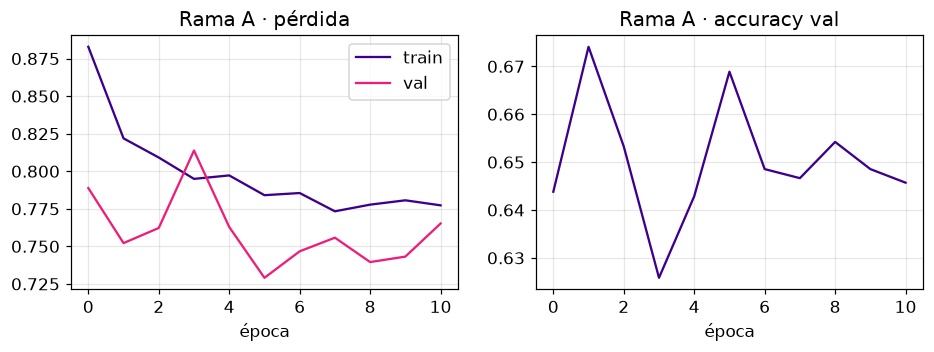

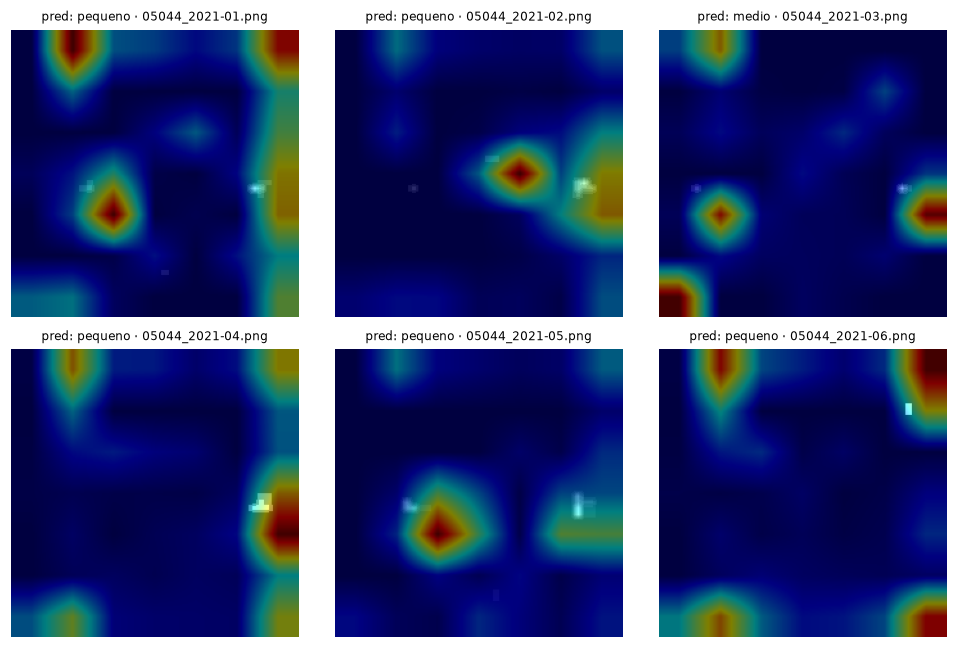

época  1 · train 0.8940 · val 0.8341 · acc val 0.611
época  2 · train 0.8484 · val 0.8540 · acc val 0.587
época  3 · train 0.8538 · val 0.8920 · acc val 0.580
época  4 · train 0.8404 · val 0.8678 · acc val 0.570
época  5 · train 0.8375 · val 0.8561 · acc val 0.581
época  6 · train 0.8386 · val 0.8414 · acc val 0.607
early stopping en época 6 (sin mejora en 5)
resnet50  · mejor val: 0.7290312526721151
effnet_b0 · mejor val: 0.8341103351217684


In [6]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Rama A · ENTRENAMIENTO (driver) — usa la maquinaria de la celda anterior
# Qué hace · parte por municipio → construye ResNet50 (Feature Extraction) → entrena con
#            early stopping → evalúa en TEST (matriz + reporte por clase) → curvas → Grad-CAM.
# E-8      · Propuesta de la IA integrada (Aceptada): registrar en bitacora-ia.md con la corrida.

import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report

dispositivo = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("dispositivo:", dispositivo)

# ── 1) partición 70/15/15 POR MUNICIPIO──
partes = partir_por_municipio()
print("recortes por parte:", {k: len(v) for k, v in partes.items()})

# ── 2) construir + entrenar ──
modelo, capa_gc = construir_cnn("resnet50", n_clases=len(CLASES), congelar=True)
hist = entrenar_cnn(modelo, partes, epocas=30, lote=32, lr=1e-3, paciencia=5,
                    etiqueta="ramaA_resnet50", dispositivo=dispositivo)

# ── 3) evaluación en TEST ──
te = DataLoader(Recortes(partes["test"], va_tf), batch_size=64)
modelo.eval()
preds, verd = [], []
with torch.no_grad():
    for xb, yb in te:
        preds += modelo(xb.to(dispositivo)).argmax(1).cpu().tolist()
        verd += yb.tolist()
cm = confusion_matrix(verd, preds, labels=[0, 1, 2])
print("matriz de confusión (test) · filas=real, columnas=pred:")
print(cm)
print(classification_report(verd, preds, target_names=CLASES, digits=2, zero_division=0))

# ── 4) curvas de entrenamiento ──
fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
ejes[0].plot(hist["train"], label="train", color=USTA_MORADO)
ejes[0].plot(hist["val"], label="val", color=USTA_ROSA)
ejes[0].set_title("Rama A · pérdida"); ejes[0].set_xlabel("época"); ejes[0].legend()
ejes[1].plot(hist["acc"], color=USTA_MORADO)
ejes[1].set_title("Rama A · accuracy val"); ejes[1].set_xlabel("época")
plt.show()

# ── 5) Grad-CAM:  evaluación ──
fig, ejes = plt.subplots(2, 3, figsize=(9, 6))
for eje, (ruta, _) in zip(ejes.ravel(), partes["test"][:6]):
    img = Image.open(ruta).convert("RGB")
    overlay, pred = grad_cam(modelo, va_tf(img), capa_gc, dispositivo=dispositivo)
    eje.imshow(overlay); eje.axis("off")
    eje.set_title(f"pred: {CLASES[pred]} · {os.path.basename(ruta)[:18]}", fontsize=8)
plt.tight_layout(); plt.show()

# ── 6) comparación de arquitecturas ──
COMPARAR_EFFICIENTNET = True      # asignar True para comparar con EfficientNet-B0 (Feature Extraction) sugerencia segunda corrida
if COMPARAR_EFFICIENTNET:
    modelo_b, _ = construir_cnn("efficientnet_b0", n_clases=len(CLASES), congelar=True)
    hist_b = entrenar_cnn(modelo_b, partes, epocas=10, lote=32, etiqueta="ramaA_effnet",
                          dispositivo=dispositivo)
    print("resnet50  · mejor val:", min(hist["val"]))
    print("effnet_b0 · mejor val:", min(hist_b["val"]))


## 2. Rama B — RNN/LSTM/GRU (serie municipal de tasa de hurto)

**Datos reales:** la serie de **tasa por 100.000 hab.** por municipio-mes del panel (8.042 observaciones en la ventana 2021 + ene–feb 2022 — supera el mínimo de 1.000 ✓). **754 municipios** tienen ≥4 meses de historia.

**Ventaneo (decisión tomada):** ventana deslizante de **6 pasos** (~4.900 ventanas de train). Justificación declarada: la historia disponible es de 14 meses — una ventana de la referencia (14 pasos) consumiría casi toda la serie (~750 ventanas) y no dejaría pares (mes t−1 → mes t) suficientes; la ventana 6 además **replica la estructura de features de la Fase 1** (tasa_1..3, media_3, media_6) — continuidad total con la línea base que se quiere superar. La actividad permite explorar otros tamaños.

**Partición (temporal, como la Fase 1):** train 2021 · validación ene-2022 · prueba feb-2022 — el modelo se evalúa en un futuro que nunca vio.

In [7]:
import json, urllib.request, hashlib, time, collections
import numpy as np

def descargar(url):
    t0 = time.time()
    with urllib.request.urlopen(url, timeout=120) as resp:
        crudo = resp.read()
    hash_ = hashlib.sha256(crudo).hexdigest()[:16]
    print(f"  {url.split('/')[-1]:<7} {len(crudo)/1e6:6.1f} MB · {time.time()-t0:4.1f} s · sha256[:16] {hash_}")
    return json.loads(crudo)

print("Descargando fuentes…")
bronce = descargar("https://intelligence-territorial-panel.vercel.app/api/dbx/bronze")["response"]
gold   = descargar("https://intelligence-territorial-panel.vercel.app/api/dbx/gold")["response"]

POB = {r["codigo_dane"]: int(r["pob_dane_2025"]) for r in gold}

def clave(r): return (r["departamento"], r["municipio"])
pref5 = lambda codigo: codigo.zfill(8)[:5]

eventos, pref_cant = {}, {}
for r in bronce:
    kk = clave(r)
    eventos[(kk, int(r["anio"]), int(r["mes"]))] = \
        eventos.get((kk, int(r["anio"]), int(r["mes"])), 0) + int(r["cantidad"])
    p = pref5(r["codigo_dane"])
    pref_cant.setdefault(kk, {})
    pref_cant[kk][p] = pref_cant[kk].get(p, 0) + 1

POBM = {}
for kk, prefijos in pref_cant.items():
    for p, _ in sorted(prefijos.items(), key=lambda t: -t[1]):
        if p in POB:
            POBM[kk] = POB[p]; break

tasa = {k3: c * 100_000 / POBM[k3[0]]
        for k3, c in eventos.items() if k3[0] in POBM}

MESES_TRAIN = [(2021, m) for m in range(1, 13)]
MESES_VAL   = [(2022, 1)]
MESES_TEST  = [(2022, 2)]
MIN_MESES_P75 = 4

def meses_previos(mes, n):
    a, mm = mes
    out = []
    for _ in range(n):
        mm -= 1
        if mm == 0: a -= 1; mm = 12
        out.append((a, mm))
    return out

# etiqueta binaria del proyecto P75
P75, excluidos = {}, 0
for kk in POBM:
    meses = [tasa[(kk,) + t] for t in MESES_TRAIN if (kk,) + t in tasa]
    if len(meses) >= MIN_MESES_P75:
        P75[kk] = float(np.percentile(meses, 75))
    else:
        excluidos += 1

# serie por municipio para la rama B
serie = collections.defaultdict(dict)
for ((dep, muni), y, m), c in eventos.items():
    if (dep, muni) in POBM:
        serie[(dep, muni)][(y, m)] = c * 100_000 / POBM[(dep, muni)]

print(f"\nmunicipios={len(POBM)} · con P75={len(P75)} · excluidos={excluidos}")
print(f"serie municipal: {len(serie)} municipios · {sum(len(s) for s in serie.values())} observaciones")

Descargando fuentes…
  bronze    46.3 MB · 20.5 s · sha256[:16] e46ba559f2204e78
  gold       4.5 MB ·  3.0 s · sha256[:16] 912b0add433d9390

municipios=1026 · con P75=709 · excluidos=317
serie municipal: 1026 municipios · 8042 observaciones


In [8]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

VENTANA = 6
torch.manual_seed(SEMILLA); np.random.seed(SEMILLA)

def crear_ventanas(serie, ventana=VENTANA):
    X, y, llaves = [], [], []
    for kk, s in serie.items():
        for (y_, m_) in sorted(s):
            objetivo = (y_, m_)
            previos = meses_previos(objetivo, ventana)
            if all(p in s for p in previos) and objetivo in s:
                X.append([s[p_] for p_ in previos])
                y.append(s[objetivo])
                llaves.append(kk + objetivo)   # (departamento, municipio, año, mes)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), llaves

X_all, y_all, ll_all = crear_ventanas(serie)

# normalización TERRITORIAL (el criterio del proyecto): cada serie se expresa relativa a la media de sus meses de TRAIN — Bogotá y Achí quedan en la misma escala,
media_propia = {}
for kk, s in serie.items():
    meses_tr = [s[t] for t in MESES_TRAIN if t in s]
    if meses_tr:
        media_propia[kk] = float(np.mean(meses_tr))
X_rel = np.array([fila / media_propia[tuple(k[:2])] for fila, k in zip(X_all, ll_all)], dtype=np.float32)
y_rel = np.array([v / media_propia[tuple(k[:2])] for v, k in zip(y_all, ll_all)], dtype=np.float32)
es_train = [k[2:] in MESES_TRAIN for k in ll_all]
es_val   = [k[2:] in MESES_VAL   for k in ll_all]
es_test  = [k[2:] in MESES_TEST  for k in ll_all]
X_tr, y_tr = X_rel[es_train], y_rel[es_train]
X_va, y_va = X_rel[es_val],   y_rel[es_val]
X_te, y_te = X_rel[es_test],  y_rel[es_test]

mu, sd = X_tr.mean(), X_tr.std()       
def esc(a): return (a - mu) / sd
X_tr_t = torch.tensor(esc(X_tr)).reshape(-1, VENTANA, 1)
X_va_t = torch.tensor(esc(X_va)).reshape(-1, VENTANA, 1)
X_te_t = torch.tensor(esc(X_te)).reshape(-1, VENTANA, 1)
y_tr_t = torch.tensor(y_tr).reshape(-1, 1)
y_va_t = torch.tensor(y_va).reshape(-1, 1)
y_te_t = torch.tensor(y_te).reshape(-1, 1)
media_te = np.array([media_propia[tuple(k[:2])] for k, t in [(k, k[2:]) for k in ll_all] if k[2:] in MESES_TEST])
print(f"ventanas (6 pasos) → train {len(y_tr)} · val {len(y_va)} · test {len(y_te)}  [≥1.000 ✓]")

# ── 2) Clase recurrente paramétrica (RNN / LSTM / GRU) ──
class Recurrente(nn.Module):
    def __init__(self, tipo="LSTM", oculta=64):
        super().__init__()
        celda = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[tipo]
        self.rec = celda(1, oculta, batch_first=True)
        self.cabeza = nn.Linear(oculta, 1)
    def forward(self, x):
        salida, _ = self.rec(x)
        return self.cabeza(salida[:, -1])

def entrenar_recurrente(modelo, epocas=50, lote=32, lr=1e-3, paciencia=5,
                        dir_ckpt="checkpoints", etiqueta="ramaB", dispositivo=None):
    dispositivo = dispositivo or ("cuda" if torch.cuda.is_available() else
                                  ("mps" if torch.backends.mps.is_available() else "cpu"))
    modelo.to(dispositivo)
    ent = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=lote, shuffle=True)
    criterio = nn.MSELoss()
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    os.makedirs(dir_ckpt, exist_ok=True)
    mejor, sin_mejora = float("inf"), 0
    hist = {"train": [], "val": []}
    for ep in range(1, epocas + 1):
        modelo.train(); tot = 0.0
        for xb, yb in ent:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            loss = criterio(modelo(xb), yb)          # 1-2. forward y pérdida
            opt.zero_grad()                          # 3. limpiar gradientes
            loss.backward()                          # 4. backward
            opt.step()                               # 5. actualizar pesos
            tot += loss.item() * len(yb)
        modelo.eval()
        with torch.no_grad():
            v = criterio(modelo(X_va_t.to(dispositivo)), y_va_t.to(dispositivo)).item()
        hist["train"].append(tot / len(ent.dataset)); hist["val"].append(v)
        if v < mejor:
            mejor, sin_mejora = v, 0
            torch.save(modelo.state_dict(), os.path.join(dir_ckpt, f"{etiqueta}_mejor.pth"))
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                print(f"  early stopping en época {ep}"); break
    modelo.load_state_dict(torch.load(os.path.join(dir_ckpt, f"{etiqueta}_mejor.pth")))
    return hist

def metricas(y_real, y_pred):
    y_real, y_pred = np.asarray(y_real), np.asarray(y_pred)
    rmse = float(np.sqrt(np.mean((y_real - y_pred) ** 2)))
    mae = float(np.mean(np.abs(y_real - y_pred)))
    mascara = y_real > 1.0                                   # MAPE solo donde la tasa es >1
    mape = float(np.mean(np.abs((y_real[mascara] - y_pred[mascara]) / y_real[mascara])) * 100)
    return rmse, mae, mape

# ── 3) Entrenamiento comparable: RNN (contraste) · LSTM · GRU ──
dispositivo = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
EP, LR, LOTE = 50, 1e-3, 32
resultados = {}
for tipo in ["RNN", "LSTM", "GRU"]:
    torch.manual_seed(SEMILLA)
    m = Recurrente(tipo=tipo)
    h = entrenar_recurrente(m, epocas=EP, lote=LOTE, lr=LR, etiqueta=f"ramaB_{tipo}",
                            dispositivo=dispositivo)
    with torch.no_grad():
        pred_rel = m(X_te_t.to(dispositivo)).cpu().numpy().ravel()      
    pred = pred_rel * media_te                                          
    rmse, mae, mape = metricas(y_te, pred)
    resultados[tipo] = (rmse, mae, mape)
    print(f"{tipo:<5} · TEST RMSE {rmse:8.2f} · MAE {mae:7.2f} · MAPE {mape:6.1f} %")

# línea ingenua (el «cursor» en unidades de tasa): y_pred = tasa(t-1)
naive = X_te[:, -1] * media_te     # ingenua relativa: tasa(t-1)/media propia
rmse_n, mae_n, mape_n = metricas(y_te, naive)
print(f"{'ingenua(t-1)':<5} · TEST RMSE {rmse_n:8.2f} · MAE {mae_n:7.2f} · MAPE {mape_n:6.1f} %")

# ── 4) Evidencia del desvanecimiento: secuencia sintética larga (admitida por la actividad) ──
def evidencia_desvanecimiento(tipo, largo=60, pasos=300, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    x = rng.standard_normal((512, largo, 1)).astype(np.float32)
    y = (x[:, :3, 0].sum(axis=1, keepdims=True) * 3.0).astype(np.float32) 
    Xt, yt = torch.tensor(x), torch.tensor(y)
    torch.manual_seed(semilla)
    m = Recurrente(tipo=tipo, oculta=64).to(dispositivo)
    opt = torch.optim.Adam(m.parameters(), lr=3e-3)
    crit = nn.MSELoss()
    ent = DataLoader(TensorDataset(Xt, yt), batch_size=64, shuffle=True)
    for _ in range(pasos):
        for xb, yb in ent:
            loss = crit(m(xb.to(dispositivo)), yb.to(dispositivo))
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return float(crit(m(Xt.to(dispositivo)), yt.to(dispositivo)))

mse_rnn = evidencia_desvanecimiento("RNN")
mse_lstm = evidencia_desvanecimiento("LSTM")
razon = (mse_rnn / mse_lstm) if mse_lstm > 0 else float("inf")
print(f"\nsecuencia larga (60 pasos, recordar los 3 primeros elementos):")
print(f"  RNN simple MSE {mse_rnn:.4f}  vs  LSTM MSE {mse_lstm:.4f}")
print(f"  → la RNN es {razon:.0f}× peor: {'✓ desvanecimiento del gradiente evidenciado' if razon > 2 else '✗ revisar configuración'}")

# ── 5) Decisión razonada GRU vs LSTM (requisito de la rúbrica) ──
rmse_l, mae_l, mape_l = resultados["LSTM"]
rmse_g, mae_g, mape_g = resultados["GRU"]
elegida = "LSTM" if rmse_l <= rmse_g else "GRU"
print(f"\nDecisión razonada: la celda elegida para la fusión es {elegida} "
      f"(RMSE test {min(rmse_l, rmse_g):.2f}); la otra se reporta como comparación.")

ventanas (6 pasos) → train 1642 · val 301 · test 306  [≥1.000 ✓]
  early stopping en época 6
RNN   · TEST RMSE    31.39 · MAE   24.87 · MAPE 2344.1 %
  early stopping en época 11
LSTM  · TEST RMSE    31.05 · MAE   24.66 · MAPE 2308.7 %
  early stopping en época 9
GRU   · TEST RMSE    28.93 · MAE   22.97 · MAPE 2145.1 %
ingenua(t-1) · TEST RMSE    31.02 · MAE   23.70 · MAPE 2257.4 %

secuencia larga (60 pasos, recordar los 3 primeros elementos):
  RNN simple MSE 0.4037  vs  LSTM MSE 0.0192
  → la RNN es 21× peor: ✓ desvanecimiento del gradiente evidenciado

Decisión razonada: la celda elegida para la fusión es GRU (RMSE test 28.93); la otra se reporta como comparación.


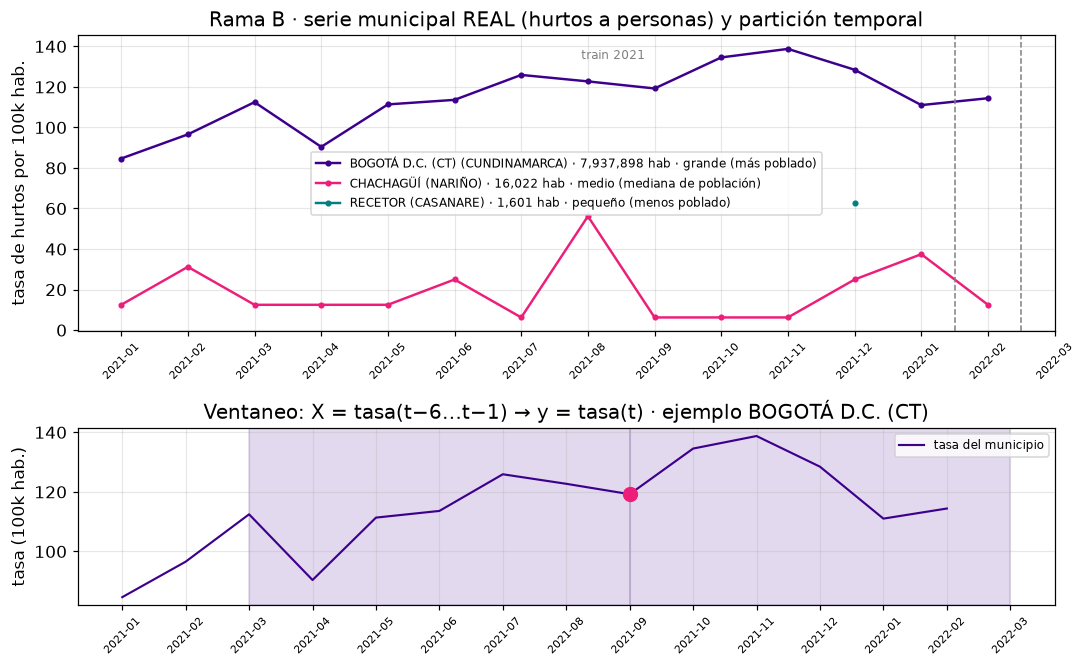

In [9]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda de soporte 4b · Serie REAL + ventaneo (visualización para el informe)
# visualización estática comentada (rúbrica criterio 5) y fig. del informe.


import numpy as np
import matplotlib.pyplot as plt

MESES_TODOS = sorted({t for s in serie.values() for t in s})         
X_POS = {t: i for i, t in enumerate(MESES_TODOS)}
ETIQ = [f"{y}-{m:02d}" for (y, m) in MESES_TODOS]

def valores(kk):
    return np.array([serie[kk].get(t, np.nan) for t in MESES_TODOS], dtype=float)

orden = sorted(POBM, key=lambda kk: -POBM[kk])
ejemplos = [(orden[0], "grande (más poblado)"),
            (orden[len(orden)//2], "medio (mediana de población)"),
            (orden[-1], "pequeño (menos poblado)")]

fig, ejes = plt.subplots(2, 1, figsize=(10, 6.2), gridspec_kw={"height_ratios": [2, 1.2]})

ax = ejes[0]
for (kk, etiqueta), color in zip(ejemplos, [USTA_MORADO, USTA_ROSA, USTA_TEAL if "USTA_TEAL" in dir() else "teal"]):
    v = valores(kk)
    ax.plot(range(len(v)), v, color=color, lw=1.6, marker="o", ms=3,
            label=f"{kk[1]} ({kk[0]}) · {POBM[kk]:,} hab · {etiqueta}")
pos_split = [X_POS[t] + 0.5 for t in MESES_TODOS if t in MESES_VAL or t in MESES_TEST]
for pos, nom in zip(pos_split, ["fin train", "fin val"]):
    ax.axvline(pos, color="gray", ls="--", lw=1)
ax.text(pos_split[0] - 5.6, ax.get_ylim()[1]*0.92, "train 2021", fontsize=8, color="gray")
ax.set_xticks(range(len(ETIQ))); ax.set_xticklabels(ETIQ, rotation=45, fontsize=7)
ax.set_ylabel("tasa de hurtos por 100k hab."); ax.legend(fontsize=8)
ax.set_title("Rama B · serie municipal REAL (hurtos a personas) y partición temporal")


ax = ejes[1]
kk = ejemplos[0][0]                      # representa municipio clasificado como grande 
v = valores(kk)
ok = ~np.isnan(v)
ax.plot(range(len(v)), v, color=USTA_MORADO, lw=1.4, label="tasa del municipio")
for inicio in [2, 8]:                    
    fin = inicio + VENTANA               # ventanas de 6 pasos (t−6…t−1) → objetivo t
    objetivo = fin                       # paso t 
    ax.axvspan(inicio, fin, color=USTA_MORADO, alpha=0.15)
    ax.plot(objetivo, v[objetivo], "o", color=USTA_ROSA, ms=9, zorder=5)
ax.annotate("ventana de 6 pasos →\nobjetivo t (● rosa)", xy=(fin, v[fin]),
            xytext=(fin + 1.5, float(np.nanmax(v)) * 0.75),
            arrowprops=dict(arrowstyle="->", color="gray"), fontsize=8)
ax.set_xticks(range(len(ETIQ))); ax.set_xticklabels(ETIQ, rotation=45, fontsize=7)
ax.set_ylabel("tasa (100k hab.)"); ax.legend(fontsize=8, loc="upper right")
ax.set_title(f"Ventaneo: X = tasa(t−{VENTANA}…t−1) → y = tasa(t) · ejemplo {kk[1]}")

plt.tight_layout(); plt.show()

## 3. Rama C — Fusión multimodal + ablación

**Continuidad con la Fase 1:** la predicción final es la **misma etiqueta binaria** del proyecto (`Alerta = 1` si la tasa del mes supera el P75 del propio municipio, calculado solo contra el train). La fusión integra lo que la CNN **ve** (imagen del mes t−1) con lo que la recurrente (ventana de 6 pasos t−6…t−1) para producir la alerta del mes t.

**Fusión tardía:** cada rama produce su embedding; se **concatenan** y una cabeza densa emite la predicción. Permite diagnosticar el aporte de cada modalidad por separado — que es exactamente el **estudio de ablación** que exige la rúbrica:

| Modelo | Qué usa | Comparación |
| --- | --- | --- |
| solo-imagen | rama A | ¿aporta la luz nocturna? |
| solo-serie | rama B | ¿aporta la memoria de la serie? |
| **fusionado** | ambas | ¿el sistema integrado supera a las ramas? |

**Referencia de comparación (continuidad del proyecto):** las líneas base de la **Fase 1** — clase mayoritaria (rec 0,00), cursor crudo (0,41) y MLP tabular (0,42) sobre el mismo test (feb-2022) — y el criterio de honestidad de la actividad: **si la fusión no supera a la mejor rama, también es un hallazgo válido** (ya lo vivimos con el cursor en la Fase 1: se documenta, no se maquilla).

>  **La decisión más importante de la Rama C**
> La fusión solo es legítima si las dos modalidades miden el **mismo par entidad-tiempo**. Nuestra clave es real y declarada desde la Propuesta:
> - **Clave de alineación: `(departamento, municipio, año-mes)`** — co-registro real por muestra: el conteo policial y el recorte satelital del mismo territorio y ventana.
> - **Desfase de 1 mes, declarado**: la imagen del mes **t−1** alimenta la alerta del mes **t** — nunca usamos la imagen del propio mes que se predice (salvedad n.° 3 de la propuesta).
> - Municipios con huecos: las filas sin imagen o sin serie **se descartan** — nunca se imputan ceros (regla del proyecto desde la Fase 1).

In [10]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda de soporte 5 · Fusión de ejemplo (FUNCIONAL)
# Qué hace · Muestra cómo concatenar un embedding de imagen (z_img) con uno temporal (z_seq)
#            en un único vector multimodal listo para la cabeza de fusión.
# Por qué  · Aísla la MECÁNICA de la concatenación; el estudiante luego conecta los
#            embeddings REALES (penúltima capa de la CNN y de la RNN) y entrena la cabeza.

import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from PIL import Image

dispositivo = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

# ── 1) código DANE dominante por municipio + clase por tercil de población ──
COD5 = {kk: max(prefijos, key=prefijos.get) for kk, prefijos in pref_cant.items()}
cods = sorted(POB.values())
C1, C2 = cods[len(cods) // 3], cods[2 * len(cods) // 3]
CLASE_KK = {kk: ("pequeno" if POBM[kk] <= C1 else ("medio" if POBM[kk] <= C2 else "grande"))
            for kk in POBM}

# ── 2) embeddings de las dos ramas ──
def z_imagen(kk, mes_prev):
    """Probs de la CNN de la rama A sobre el recorte del mes t−1 (la imagen más reciente sin fuga)."""
    png = os.path.join("data/imagenes", CLASE_KK[kk], f"{COD5[kk]}_{mes_prev[0]}-{mes_prev[1]:02d}.png")
    t = va_tf(Image.open(png).convert("RGB")).unsqueeze(0).to(dispositivo)
    with torch.no_grad():
        return torch.softmax(modelo(t), dim=1)[0].cpu().numpy()

def z_serie(kk, mes_obj, ventana=6):
    """Los 6 lags de la serie del municipio, relativos a su media propia (t−6…t−1)."""
    s = serie[kk]
    previos = meses_previos(mes_obj, ventana)
    media = float(np.mean([s[t] for t in MESES_TRAIN if t in s]))
    return np.array([s[p_] / media for p_ in previos], dtype=np.float32)

# ── 3) dataset de fusión (alineación por municipio-mes) ──
filas = {"train": [], "val": [], "test": []}
for kk, s in serie.items():
    if kk not in P75 or kk not in COD5:
        continue
    for (y_, m_) in sorted(s):
        t = (y_, m_)
        previos = meses_previos(t, 6)
        if not (all(p in s for p in previos) and t in s):
            continue
        mes_prev = previos[-1]
        png = os.path.join("data/imagenes", CLASE_KK[kk],
                           f"{COD5[kk]}_{mes_prev[0]}-{mes_prev[1]:02d}.png")
        if not os.path.exists(png):
            continue
        z = np.concatenate([z_imagen(kk, mes_prev), z_serie(kk, t)])
        y_ = 1.0 if s[t] > P75[kk] else 0.0
        parte = "train" if t in MESES_TRAIN else ("val" if t in MESES_VAL else "test")
        filas[parte].append((z, y_))
print("muestras de fusión:", {k: len(v) for k, v in filas.items()})

def a_tensores(filas_parte, dim):
    X = np.stack([f[0][:dim] for f in filas_parte]).astype(np.float32)
    y = np.array([f[1] for f in filas_parte], dtype=np.float32)
    return (torch.tensor(X).to(dispositivo), torch.tensor(y).reshape(-1, 1).to(dispositivo))

# ── 4) cabeza de fusión + entrenamiento (los 5 pasos, early stopping) ──
class Cabeza(nn.Module):
    def __init__(self, n_entrada, oculta=16):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(n_entrada, oculta), nn.ReLU(),
                                 nn.Dropout(0.2), nn.Linear(oculta, 1))
    def forward(self, x):
        return self.red(x)

def entrenar_cabeza(modelo, X_t, y_t, Xv_t, yv_t, epocas=50, lr=1e-3, paciencia=5,
                    dir_ckpt="checkpoints", etiqueta="ramaC"):
    ent = DataLoader(TensorDataset(X_t, y_t), batch_size=32, shuffle=True)
    criterio = nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    os.makedirs(dir_ckpt, exist_ok=True)
    mejor, sin_mejora = float("inf"), 0
    for ep in range(1, epocas + 1):
        modelo.train(); tot = 0.0
        for xb, yb in ent:
            loss = criterio(modelo(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(yb)
        modelo.eval()
        with torch.no_grad():
            v = criterio(modelo(Xv_t), yv_t).item()
        if v < mejor:
            mejor, sin_mejora = v, 0
            torch.save(modelo.state_dict(), os.path.join(dir_ckpt, f"{etiqueta}_mejor.pth"))
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                print(f"  early stopping en época {ep}"); break
    return mejor

def reporte(nombre, modelo, X_t, y_real):
    modelo.eval()
    with torch.no_grad():
        p = (modelo(X_t) >= 0).float().cpu().numpy().ravel()
    y = np.asarray(y_real.cpu() if torch.is_tensor(y_real) else y_real).astype(int)
    from sklearn.metrics import confusion_matrix
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    print(f"{nombre:<24} acc {(tp + tn) / len(y):.2f} · rec alerta {tp / max(tp + fn, 1):.2f}"
          f" · (tp,fp,fn,tn)=({tp},{fp},{fn},{tn})")

# ── 5) ABLACIÓN: las tres cabezas sobre el MISMO test ──
os.makedirs("checkpoints", exist_ok=True)
print("\n── ABLACIÓN (prueba feb-2022) ──")
for nombre, dim in [("solo-imagen", 3), ("solo-serie", 6), ("fusionado", 9)]:
    torch.manual_seed(SEMILLA)
    m = Cabeza(dim).to(dispositivo)
    Xtr, ytr = a_tensores(filas["train"], dim)
    Xva, yva = a_tensores(filas["val"], dim)
    Xte, yte = a_tensores(filas["test"], dim)
    entrenar_cabeza(m, Xtr, ytr, Xva, yva, epocas=50, etiqueta=f"ramaC_{nombre.split('-')[-1]}")
    reporte(nombre, m, Xte, yte)

print("\nReferencia Fase 1 (mismo test, en recall): mayoría 0,00 · cursor 0,41 · MLP 0,42")
print("Criterio de honestidad: si el fusionado no supera a la mejor rama, es un hallazgo válido")
print("y se documenta con su por qué (modalidad redundante, alineación agregada, datos cortos).")

muestras de fusión: {'train': 1629, 'val': 298, 'test': 320}

── ABLACIÓN (prueba feb-2022) ──
  early stopping en época 10
solo-imagen              acc 0.76 · rec alerta 0.00 · (tp,fp,fn,tn)=(0,0,78,242)
  early stopping en época 7
solo-serie               acc 0.76 · rec alerta 0.00 · (tp,fp,fn,tn)=(0,0,78,242)
  early stopping en época 7
fusionado                acc 0.76 · rec alerta 0.00 · (tp,fp,fn,tn)=(0,0,78,242)

Referencia Fase 1 (mismo test, en recall): mayoría 0,00 · cursor 0,41 · MLP 0,42
Criterio de honestidad: si el fusionado no supera a la mejor rama, es un hallazgo válido
y se documenta con su por qué (modalidad redundante, alineación agregada, datos cortos).


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Rama C · FUSIÓN CON EMBEDDINGS REALES + ABLACIÓN (implementación definitiva)
# Qué hace · reutiliza las dos ramas entrenadas como extractores: z_img = penúltima capa de
#            la ResNet50 (2048-d) y z_seq = estado oculto final de la GRU/LSTM elegida (64-d).
#            Cabeza densa con Dropout → alerta binaria (tasa > P75 del municipio) y ablación
#            de 3 cabezas (solo-imagen / solo-serie / fusionado) sobre el MISMO test feb-2022.
# E-12     · Implementación de la rama C (reemplaza el stub; la mecánica demo está en la
#            celda 20). Requiere: celda 12 corrida («modelo») y celda 15 corrida («elegida»).

import os
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import confusion_matrix

dispositivo = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

# ── 0) autosuficiencia: CLASE_KK y COD5 (si la celda 20 no se ha corrido) ──
if "CLASE_KK" not in dir() or "COD5" not in dir():
    COD5 = {kk: max(prefijos, key=prefijos.get) for kk, prefijos in pref_cant.items()}
    cods = sorted(POB.values())
    C1, C2 = cods[len(cods) // 3], cods[2 * len(cods) // 3]
    CLASE_KK = {kk: ("pequeno" if POBM[kk] <= C1 else ("medio" if POBM[kk] <= C2 else "grande"))
                for kk in POBM}
    print("CLASE_KK/COD5 reconstruidos localmente (la celda 20 no había corrido)")

# ── 1) extractores de embeddings de las dos ramas ──
assert "modelo" in dir(), "Primero corre la celda 12 (rama A): define «modelo» entrenado."
assert "elegida" in dir(), "Primero corre la celda 15 (rama B): define «elegida» (GRU/LSTM)."

modelo.eval()                                  
extractor_img = nn.Sequential(*list(modelo.children())[:-1])   
extractor_img.to(dispositivo).eval()

gru = Recurrente(tipo=elegida)                 
gru.load_state_dict(torch.load(f"checkpoints/ramaB_{elegida}_mejor.pth", map_location="cpu"))
gru.to(dispositivo).eval()

def z_img(ruta):
    """Penúltima capa de la CNN sobre el recorte del mes t−1 """
    t = va_tf(Image.open(ruta).convert("RGB")).unsqueeze(0).to(dispositivo)
    with torch.no_grad():
        return extractor_img(t).flatten(1)[0].cpu().numpy()

def z_seq(kk, t):
    previos = meses_previos(t, 6)
    vals = np.array([serie[kk][p_] / media_propia[kk] for p_ in previos], dtype=np.float32)
    x = torch.tensor(esc(vals)).reshape(1, VENTANA, 1).to(dispositivo)
    with torch.no_grad():
        salida, _ = gru.rec(x)
    return salida[:, -1][0].cpu().numpy()

# ── 2) dataset de fusión: llave de alineación (municipio, mes), desfase t−1 → alerta t ──
DIM_IMG, DIM_SEQ = 2048, gru.rec.hidden_size
filas = {"train": [], "val": [], "test": []}
vistos = 0
for kk, s in serie.items():
    if kk not in P75 or kk not in COD5:
        continue
    for (y_, m_) in sorted(s):
        t = (y_, m_)
        previos = meses_previos(t, 6)
        if not (all(p in s for p in previos) and t in s):
            continue
        mes_prev = previos[-1]
        png = os.path.join("data/imagenes", CLASE_KK[kk],
                           f"{COD5[kk]}_{mes_prev[0]}-{mes_prev[1]:02d}.png")
        if not os.path.exists(png):
            continue
        zi, zs = z_img(png), z_seq(kk, t)
        etiqueta = 1.0 if s[t] > P75[kk] else 0.0
        parte = "train" if t in MESES_TRAIN else ("val" if t in MESES_VAL else "test")
        filas[parte].append((zi, zs, etiqueta))
        vistos += 1
        if vistos % 1000 == 0:
            print(f"  … {vistos} municipio-meses procesados")
print("muestras de fusión:", {k: len(v) for k, v in filas.items()})

X_img = {p: np.stack([f[0] for f in filas[p]]).astype(np.float32) for p in filas}
X_seq = {p: np.stack([f[1] for f in filas[p]]).astype(np.float32) for p in filas}
Y     = {p: np.array([f[2] for f in filas[p]], dtype=np.float32) for p in filas}

def tensores(p, mascara):
    X = torch.tensor(np.concatenate([X_img[p], X_seq[p]], axis=1)[:, mascara]).to(dispositivo)
    y = torch.tensor(Y[p]).reshape(-1, 1).to(dispositivo)
    return X, y

# ── 3) cabeza de fusión──
class Cabeza(nn.Module):
    def __init__(self, n_entrada, oculta=64):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(n_entrada, oculta), nn.ReLU(),
                                 nn.Dropout(0.3), nn.Linear(oculta, 1))
    def forward(self, x):
        return self.red(x)

def entrenar_cabeza(m, Xtr, ytr, Xva, yva, epocas=50, lr=1e-3, paciencia=5,
                    dir_ckpt="checkpoints", etiqueta="ramaC"):
    ent = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True)
    criterio = nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    os.makedirs(dir_ckpt, exist_ok=True)
    mejor, sin_mejora = float("inf"), 0
    for ep in range(1, epocas + 1):
        m.train(); tot = 0.0
        for xb, yb in ent:
            loss = criterio(m(xb), yb)               
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(yb)
        m.eval()
        with torch.no_grad():
            v = criterio(m(Xva), yva).item()
        if v < mejor:
            mejor, sin_mejora = v, 0
            torch.save(m.state_dict(), os.path.join(dir_ckpt, f"{etiqueta}_mejor.pth"))
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                print(f"    early stopping en época {ep}"); break
    m.load_state_dict(torch.load(os.path.join(dir_ckpt, f"{etiqueta}_mejor.pth")))
    return mejor

def reporte(nombre, m, Xte, yte):
    m.eval()
    with torch.no_grad():
        p = (m(Xte) >= 0).float().cpu().numpy().ravel()
    y = yte.cpu().numpy().ravel().astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    print(f"{nombre:<24} acc {(tp + tn) / len(y):.2f} · recall alerta {tp / max(tp + fn, 1):.2f}"
          f" · (tp,fp,fn,tn)=({tp},{fp},{fn},{tn})")

# ── 4) ABLACIÓN: tres cabezas sobre el MISMO test de feb-2022 ──
print(f"\n── ABLACIÓN con embeddings reales (z_img {DIM_IMG}-d · z_seq {DIM_SEQ}-d) · prueba feb-2022 ──")
for nombre, mascara in [("solo-imagen", slice(0, DIM_IMG)),
                        ("solo-serie", slice(DIM_IMG, DIM_IMG + DIM_SEQ)),
                        ("fusionado", slice(0, DIM_IMG + DIM_SEQ))]:
    torch.manual_seed(SEMILLA)
    Xtr, ytr = tensores("train", mascara)
    Xva, yva = tensores("val", mascara)
    Xte, yte = tensores("test", mascara)
    m = Cabeza(Xtr.shape[1]).to(dispositivo)
    entrenar_cabeza(m, Xtr, ytr, Xva, yva, epocas=50,
                    etiqueta=f"ramaC_{nombre.split('-')[-1]}")
    reporte(nombre, m, Xte, yte)

print("\nReferencia Fase 1 (mismo test, en recall): mayoría 0,00 · cursor 0,41 · MLP 0,42")
print("Criterio de honestidad: si el fusionado no supera a la mejor rama, es un hallazgo válido")
print("y se documenta con su por qué (modalidad redundante, alineación agregada, datos cortos).")

  … 1000 municipio-meses procesados
  … 2000 municipio-meses procesados
muestras de fusión: {'train': 1629, 'val': 298, 'test': 320}

── ABLACIÓN con embeddings reales (z_img 2048-d · z_seq 64-d) · prueba feb-2022 ──
    early stopping en época 6
solo-imagen              acc 0.76 · recall alerta 0.00 · (tp,fp,fn,tn)=(0,0,78,242)
    early stopping en época 6
solo-serie               acc 0.76 · recall alerta 0.00 · (tp,fp,fn,tn)=(0,0,78,242)
    early stopping en época 6
fusionado                acc 0.76 · recall alerta 0.00 · (tp,fp,fn,tn)=(0,0,78,242)

Referencia Fase 1 (mismo test, en recall): mayoría 0,00 · cursor 0,41 · MLP 0,42
Criterio de honestidad: si el fusionado no supera a la mejor rama, es un hallazgo válido
y se documenta con su por qué (modalidad redundante, alineación agregada, datos cortos).



**Bloqueos abiertos de este cuaderno:**
1. 🔒 **Rama A**: cuenta NASA Earthdata (registrarse en https://urs.earthdata.nasa.gov) → descarga de los 14 compuestos VNP46A3 → polígonos ya resueltos por la API del panel (caché en `data/MGN/`).
2. ⏳ **Grad-CAM y ablación completa**: dependen de la rama A.

### 🔗 Relacionado
- Actividad oficial: [21_Modulo_2_Actividad_Fase2_Centinela](https://jotamao1985.github.io/Deep_Learning_Usta/21_Modulo_2_Actividad_Fase2_Centinela.html) · Andamiaje del curso (del que este cuaderno clona la estructura).
- Material del Módulo 2: [02_Modulo_2_Arquitecturas](https://jotamao1985.github.io/Deep_Learning_Usta/02_Modulo_2_Arquitecturas_Deep_Learning.html) (Caps. 2.1 CNN/ViT · 2.2 RNN/LSTM/GRU · 2.3 generativos) · [material de consulta](https://jotamao1985.github.io/Deep_Learning_Usta/021_material-consulta-modulo-2.html).
- Ejemplo resuelto **vetado como entrega**: sistema del tulipán (`06-ejemplo-centinela-fase2-tulipanes.ipynb`) — sirve para calibrar el nivel.
- Documento maestro: Proyecto Integrador Centinela · Fase 3 (despliegue offline, GPU, precisión mixta — la optimización para borde no entra en esta fase).